# Insurance Cost Prediction - Exploratory Data Analysis

## Project Overview

This project focuses on predicting medical insurance charges using personal and lifestyle-related features such as age, sex, BMI, number of children, smoking status, and region.

The main goal of this notebook is to explore the dataset, understand the feature distributions, identify relationships between variables, and prepare insights before building machine learning regression models.

## Dataset Description

The dataset contains information about medical insurance customers.

### Features

- **age**: Age of the insurance customer
- **sex**: Gender of the customer
- **bmi**: Body Mass Index
- **children**: Number of children/dependents covered by insurance
- **smoker**: Whether the customer is a smoker or non-smoker
- **region**: Residential region of the customer
- **charges**: Medical insurance cost charged to the customer

## Objective

The target variable is **charges**.  
This is a regression problem because the model needs to predict a continuous numerical value.

## 1. Import Required Libraries

In this section, we import the Python libraries required for data analysis and visualization.

- **pandas** is used for loading and handling the dataset.
- **numpy** is used for numerical operations.
- **matplotlib** and **seaborn** are used for creating visualizations.

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Display all columns clearly
pd.set_option("display.max_columns", None)

## 2. Load the Dataset

The dataset is loaded from the `data` folder. After loading the dataset, we display the shape of the dataset and view the first few records.

In [2]:
# Load the dataset

df = pd.read_csv("../data/insurance.csv")


print(f"Dataset shape: {df.shape}")

df.head()

Dataset shape: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 3. Dataset Overview

Before performing detailed analysis, it is important to understand the basic structure of the dataset.

In this section, we check:

- Dataset information such as column names, data types, and non-null values
- Summary statistics of numerical and categorical columns
- Missing values
- Duplicate records

This helps us identify whether the dataset needs cleaning before visualization and model building.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


### Observation

The dataset contains **1338 records** and **7 columns**.

There are:

- 2 integer columns: `age`, `children`
- 2 float columns: `bmi`, `charges`
- 3 categorical columns: `sex`, `smoker`, `region`

The target variable is `charges`, which represents the medical insurance cost.

In [4]:
df.describe(include='all').round(2)

,age,sex,bmi,children,smoker,region,charges
count,1338.00,1338,1338.00,1338.00,1338,1338,1338.00
unique,NaN,2,NaN,NaN,2,4,NaN
top,NaN,male,NaN,NaN,no,southeast,NaN
freq,NaN,676,NaN,NaN,1064,364,NaN
mean,39.21,NaN,30.66,1.09,NaN,NaN,13270.42
std,14.05,NaN,6.10,1.21,NaN,NaN,12110.01
min,18.00,NaN,15.96,0.00,NaN,NaN,1121.87
25%,27.00,NaN,26.30,0.00,NaN,NaN,4740.29
50%,39.00,NaN,30.40,1.00,NaN,NaN,9382.03
75%,51.00,NaN,34.69,2.00,NaN,NaN,16639.91


### Summary Statistics Interpretation

From the summary statistics:

- The average customer age is around **39 years**.
- The average BMI is around **30.66**, which is close to the obese BMI range.
- The average insurance charge is around **13,270**.
- The minimum insurance charge is around **1,121**, while the maximum is around **63,770**.
- Most customers are **non-smokers**.
- The most common region is **southeast**.

These values give an initial understanding of the dataset before deeper analysis.

In [5]:
# Check missing values and duplicate records

missing_values = df.isnull().sum()
duplicate_rows = df.duplicated().sum()

print("Missing values in each column:")
print(missing_values)

print("\nTotal missing values:", missing_values.sum())
print("Duplicate rows:", duplicate_rows)

Missing values in each column:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Total missing values: 0
Duplicate rows: 1


### Data Quality Observation

The dataset does not contain any missing values, which means no missing value treatment is required at this stage.

However, there is **1 duplicate row** in the dataset. This duplicate record should be removed during the data cleaning stage to avoid repeated information affecting the model.

In [6]:
# Create a missing value summary table

missing_summary = pd.DataFrame({
    "Column": df.columns,
    "Missing Values": df.isnull().sum().values,
    "Missing Percentage": (df.isnull().sum().values / len(df) * 100).round(2)
})

missing_summary

,Column,Missing Values,Missing Percentage
0,age,0,0.0
1,sex,0,0.0
2,bmi,0,0.0
3,children,0,0.0
4,smoker,0,0.0
5,region,0,0.0
6,charges,0,0.0


## 4. Target Variable Distribution

The target variable in this project is `charges`.

Since this is a regression problem, it is important to understand how the target variable is distributed before building machine learning models.

In this section, we analyze:

- The distribution of insurance charges
- Whether the target variable is normally distributed or skewed
- The effect of applying a log transformation to reduce skewness

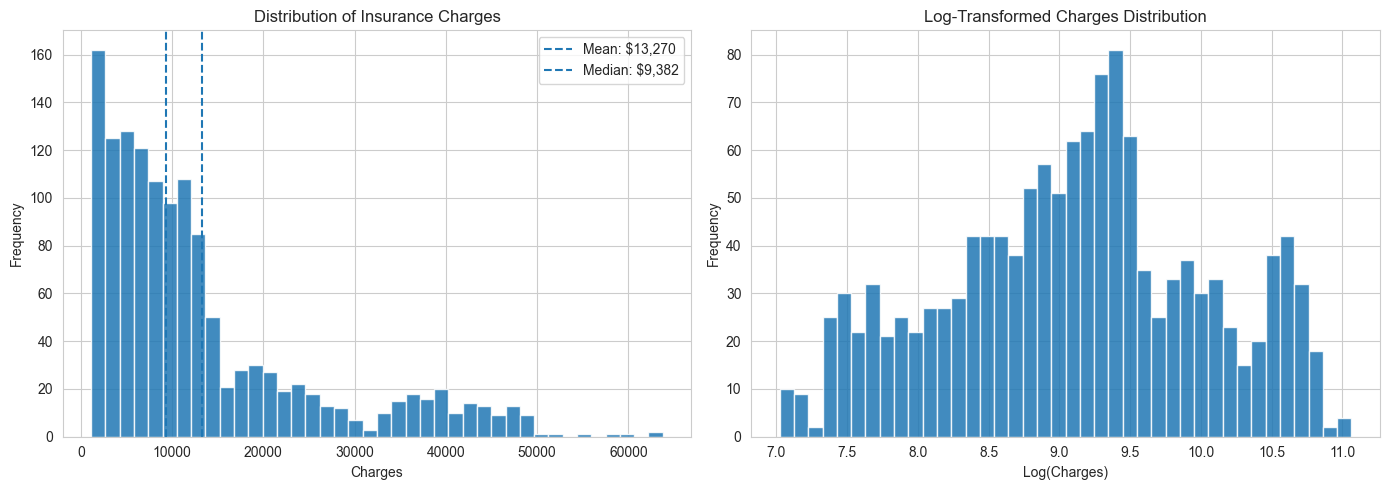

Skewness of charges: 1.52
Skewness of log-transformed charges: -0.09


In [7]:
# Plot the distribution of the target variable

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Original charges distribution
axes[0].hist(df["charges"], bins=40, edgecolor="white", alpha=0.85)
axes[0].axvline(df["charges"].mean(), linestyle="--", label=f"Mean: ${df['charges'].mean():,.0f}")
axes[0].axvline(df["charges"].median(), linestyle="--", label=f"Median: ${df['charges'].median():,.0f}")
axes[0].set_title("Distribution of Insurance Charges")
axes[0].set_xlabel("Charges")
axes[0].set_ylabel("Frequency")
axes[0].legend()

# Log-transformed charges distribution
log_charges = np.log1p(df["charges"])

axes[1].hist(log_charges, bins=40, edgecolor="white", alpha=0.85)
axes[1].set_title("Log-Transformed Charges Distribution")
axes[1].set_xlabel("Log(Charges)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

# Display skewness values
print(f"Skewness of charges: {df['charges'].skew():.2f}")
print(f"Skewness of log-transformed charges: {log_charges.skew():.2f}")

### Observation

The original `charges` variable is **right-skewed**. This means that most customers have lower insurance charges, while a smaller number of customers have very high charges.

The mean value is higher than the median value, which also confirms the presence of right skewness.

After applying a log transformation, the distribution becomes more balanced and closer to a normal distribution. This is useful because some regression models perform better when the target variable is less skewed.

However, in this project, we will first build models using the original `charges` value and later compare whether transformation improves model performance.

## 5. Univariate Analysis - Numerical Features

Univariate analysis means analyzing one variable at a time.

In this section, we analyze the numerical input features:

- `age`
- `bmi`
- `children`

For each numerical feature, we use:

- **Histogram** to understand the distribution
- **Boxplot** to identify spread and possible outliers

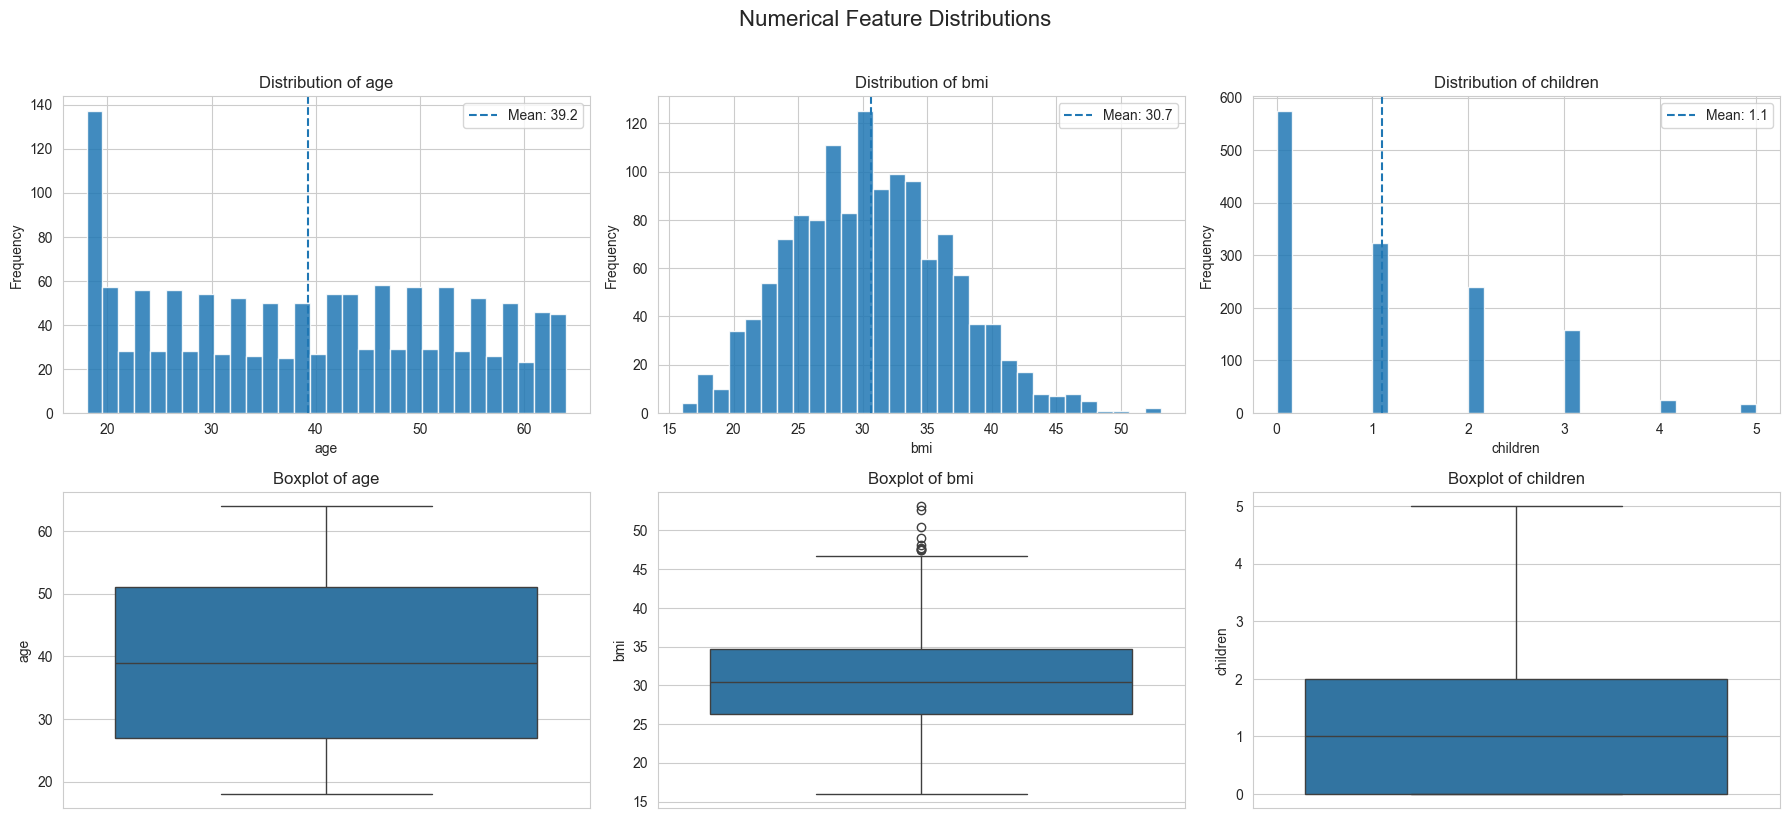

In [8]:
# Select numerical features for univariate analysis

num_features = ["age", "bmi", "children"]

fig, axes = plt.subplots(2, 3, figsize=(18, 8))

for i, col in enumerate(num_features):
    
    # Histogram
    axes[0, i].hist(df[col], bins=30, edgecolor="white", alpha=0.85)
    axes[0, i].axvline(
        df[col].mean(),
        linestyle="--",
        label=f"Mean: {df[col].mean():.1f}"
    )
    axes[0, i].set_title(f"Distribution of {col}")
    axes[0, i].set_xlabel(col)
    axes[0, i].set_ylabel("Frequency")
    axes[0, i].legend()
    
    # Boxplot
    sns.boxplot(y=df[col], ax=axes[1, i])
    axes[1, i].set_title(f"Boxplot of {col}")
    axes[1, i].set_ylabel(col)

plt.suptitle("Numerical Feature Distributions", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

### Observation

From the numerical feature distributions:

- **Age** values are spread between 18 and 64 years. The dataset contains customers from young adults to older adults.
- **BMI** is mostly concentrated around 25 to 35. Some customers have high BMI values, which appear as possible outliers in the boxplot.
- **Children** is a discrete numerical feature. Most customers have 0 to 2 children, while only a small number of customers have 4 or 5 children.

The BMI feature may be important for predicting insurance charges because higher BMI can be related to higher medical risk. Age may also be an important feature because medical expenses often increase as age increases.

## 6. Univariate Analysis - Categorical Features

In this section, we analyze the categorical input features:

- `sex`
- `smoker`
- `region`

Categorical feature analysis helps us understand how many customers belong to each category. This is useful because categorical variables such as smoking status and region may influence insurance charges.

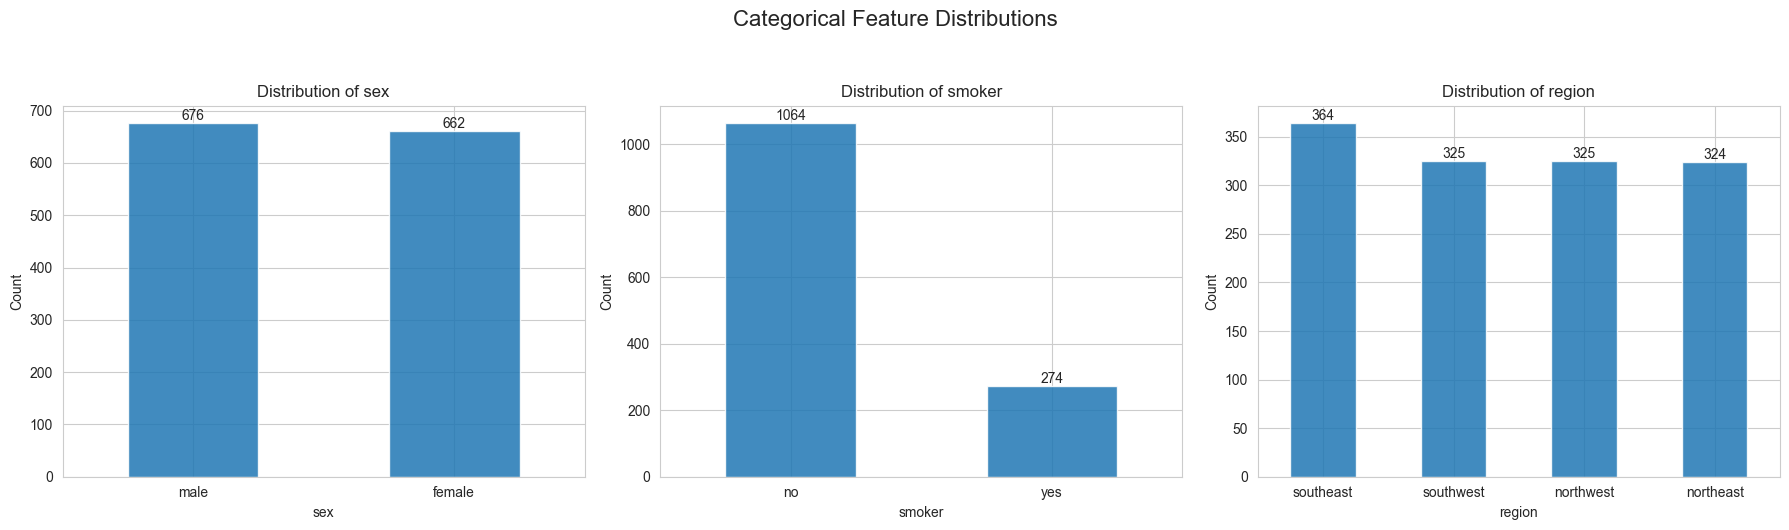

In [9]:
# Select categorical features for univariate analysis

cat_features = ["sex", "smoker", "region"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(cat_features):
    counts = df[col].value_counts()
    
    counts.plot(kind="bar", ax=axes[i], edgecolor="white", alpha=0.85)
    
    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Count")
    axes[i].tick_params(axis="x", rotation=0)
    
    # Add count labels on top of bars
    for container in axes[i].containers:
        axes[i].bar_label(container)

plt.suptitle("Categorical Feature Distributions", fontsize=16, y=1.05)
plt.tight_layout()
plt.show()

In [10]:
# Display categorical feature counts and percentages

for col in cat_features:
    print(f"\n{col.upper()} distribution:")
    display(
        pd.DataFrame({
            "Count": df[col].value_counts(),
            "Percentage (%)": df[col].value_counts(normalize=True).mul(100).round(2)
        })
    )


SEX distribution:


,Count,Percentage (%)
sex,,
male,676,50.52
female,662,49.48



SMOKER distribution:


,Count,Percentage (%)
smoker,,
no,1064,79.52
yes,274,20.48



REGION distribution:


,Count,Percentage (%)
region,,
southeast,364,27.20
southwest,325,24.29
northwest,325,24.29
northeast,324,24.22


### Observation

From the categorical feature distributions:

- The `sex` feature is almost balanced, with a similar number of male and female customers.
- The `smoker` feature is imbalanced because there are many more non-smokers than smokers.
- The `region` feature is fairly balanced across the four regions, although the southeast region has the highest number of records.

Smoking status is expected to be an important feature because smokers usually have higher medical risks, which may increase insurance charges.

## 7. Bivariate Analysis - Numerical Features vs Charges

Bivariate analysis is used to study the relationship between two variables.

In this section, we compare the numerical input features with the target variable `charges`.

We analyze:

- `age` vs `charges`
- `bmi` vs `charges`
- `children` vs `charges`

Scatter plots are used to check whether these numerical features show a positive, negative, or weak relationship with insurance charges.

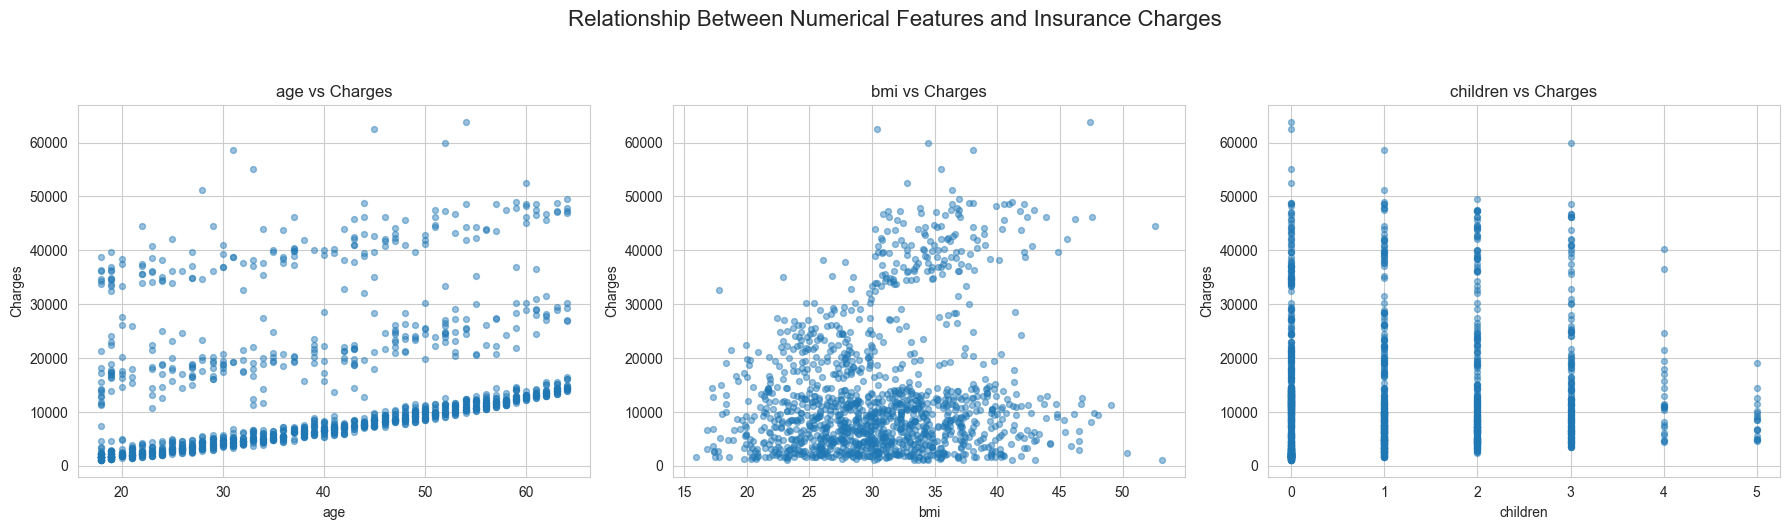

In [11]:
# Analyze relationship between numerical features and insurance charges

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(num_features):
    axes[i].scatter(df[col], df["charges"], alpha=0.45, s=18)
    axes[i].set_title(f"{col} vs Charges")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Charges")
    
plt.suptitle("Relationship Between Numerical Features and Insurance Charges", fontsize=16, y=1.05)
plt.tight_layout()
plt.show()

In [12]:
# Calculate Pearson correlation between numerical features and charges

correlation_with_charges = df[num_features + ["charges"]].corr()["charges"].drop("charges").sort_values(ascending=False)

print("Pearson correlation with charges:")
correlation_with_charges.round(3)

Pearson correlation with charges:


age         0.299
bmi         0.198
children    0.068
Name: charges, dtype: float64

### Observation

From the scatter plots and correlation values:

- **Age** has the strongest positive relationship with insurance charges among the numerical features. As age increases, insurance charges generally tend to increase.
- **BMI** has a weak positive relationship with charges. Higher BMI may contribute to higher charges, but the relationship is not very strong by itself.
- **Children** has a very weak relationship with charges, meaning the number of children does not strongly affect insurance charges in this dataset.

The correlation results show:

- `age` has a correlation of around **0.299** with charges.
- `bmi` has a correlation of around **0.198** with charges.
- `children` has a correlation of around **0.068** with charges.

This suggests that numerical features alone do not fully explain insurance charges. Other categorical features, especially `smoker`, may have a stronger effect.

## 8. Bivariate Analysis - Categorical Features vs Charges

In this section, we compare the categorical input features with the target variable `charges`.

We analyze:

- `sex` vs `charges`
- `smoker` vs `charges`
- `region` vs `charges`

Boxplots are used to compare the distribution of insurance charges across different categories. This helps identify which categorical features may strongly affect insurance costs.

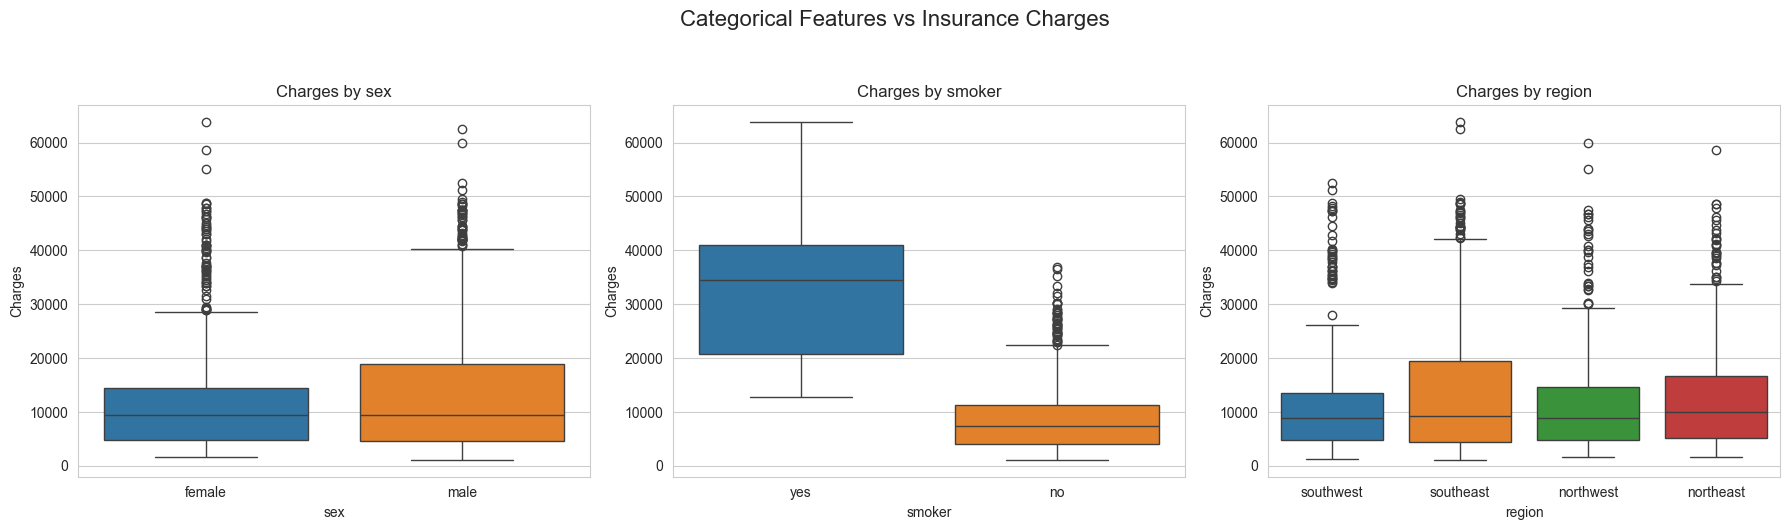

In [13]:
# Analyze relationship between categorical features and insurance charges

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(cat_features):
    sns.boxplot(
        data=df,
        x=col,
        y="charges",
        hue=col,
        ax=axes[i],
        legend=False
    )
    
    axes[i].set_title(f"Charges by {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Charges")
    axes[i].tick_params(axis="x", rotation=0)

plt.suptitle("Categorical Features vs Insurance Charges", fontsize=16, y=1.05)
plt.tight_layout()
plt.show()

In [14]:
# Calculate mean, median, and count of charges for each categorical feature

for col in cat_features:
    print(f"\n{col.upper()} - Charges Summary:")
    
    summary = df.groupby(col)["charges"].agg(["mean", "median", "count"]).round(2)
    display(summary)


SEX - Charges Summary:


,mean,median,count
sex,,,
female,12569.58,9412.96,662
male,13956.75,9369.62,676



SMOKER - Charges Summary:


,mean,median,count
smoker,,,
no,8434.27,7345.41,1064
yes,32050.23,34456.35,274



REGION - Charges Summary:


,mean,median,count
region,,,
northeast,13406.38,10057.65,324
northwest,12417.58,8965.80,325
southeast,14735.41,9294.13,364
southwest,12346.94,8798.59,325


### Observation

From the categorical feature analysis:

- **Sex** does not show a very large difference in insurance charges between male and female customers.
- **Smoker** shows a very strong effect on insurance charges. Smokers have much higher medical insurance charges compared to non-smokers.
- **Region** shows some variation in charges, but the difference is not as strong as smoking status.

The `smoker` feature appears to be one of the most important predictors in this dataset because it creates a clear separation in insurance charges.

## 9. Smoker and BMI Deep-Dive

From the previous analysis, smoking status showed a strong effect on insurance charges.

In this section, we analyze the relationship between:

- `bmi`
- `smoker`
- `charges`

This is important because customers who are both **smokers** and have a **high BMI** may have much higher medical risk, which can lead to higher insurance charges.

A BMI value of **30 or above** is commonly treated as the obese category in this project.## 9. Smoker × BMI Deep-Dive

The single most important interaction in this dataset: smokers with high BMI pay dramatically more.

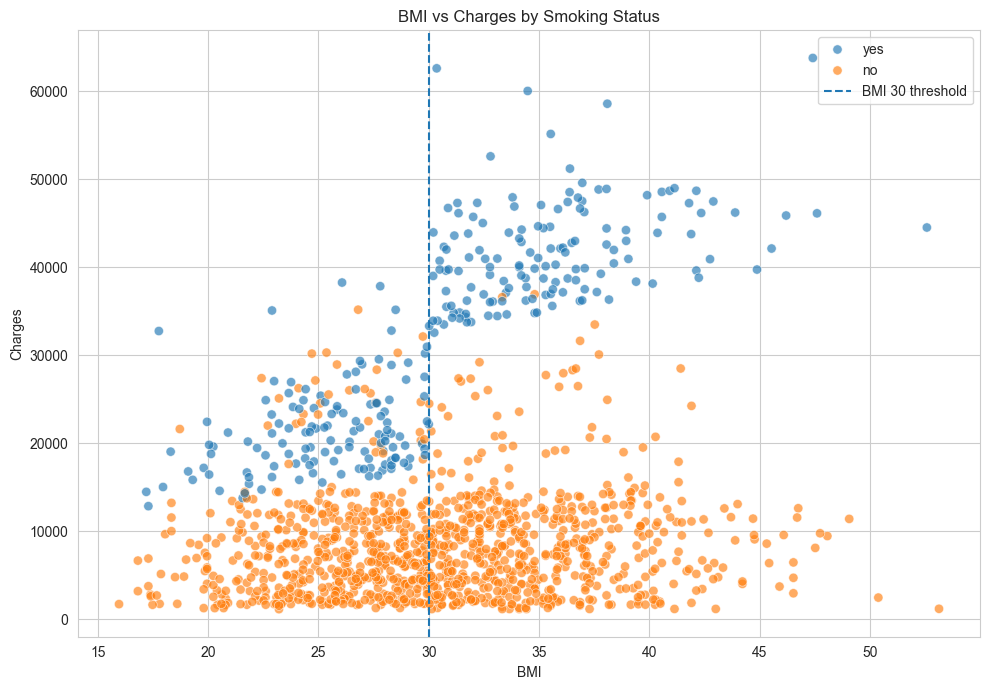

In [15]:
# Analyze the relationship between BMI, smoking status, and insurance charges

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x="bmi",
    y="charges",
    hue="smoker",
    alpha=0.65,
    s=45
)

# Add BMI threshold line
plt.axvline(30, linestyle="--", label="BMI 30 threshold")

plt.title("BMI vs Charges by Smoking Status")
plt.xlabel("BMI")
plt.ylabel("Charges")
plt.legend()
plt.tight_layout()
plt.show()

In [16]:
# Create BMI obesity category for deeper comparison

df["bmi_group"] = np.where(df["bmi"] >= 30, "obese", "non-obese")

# Calculate mean charges by smoker status and BMI group
smoker_bmi_summary = (
    df.groupby(["smoker", "bmi_group"])["charges"]
    .agg(["mean", "median", "count"])
    .round(2)
)

smoker_bmi_summary

mean    median  count
smoker bmi_group                           
no     non-obese   7977.03   6761.62    502
       obese       8842.69   8076.05    562
yes    non-obese  21363.22  20167.34    129
       obese      41557.99  40904.20    145

### Smoker and BMI Summary

The summary table confirms that insurance charges are highest for customers who are both **smokers** and **obese**.

Compared with non-smokers, smokers have much higher average charges in both BMI groups. However, the highest average cost appears in the smoker-obese group.

This supports the idea that `smoker` is a major predictor and that combining smoking status with BMI can create a useful engineered feature for model building.

## 10. Correlation Analysis

Correlation analysis helps us understand the strength and direction of relationships between numerical variables.

Since the dataset contains categorical variables, they need to be converted into numerical form before calculating correlation.

In this section:

- `sex` is encoded as a binary variable
- `smoker` is encoded as a binary variable
- `region` is converted using one-hot encoding
- A heatmap is used to visualize correlations
- A bar chart is used to identify the features most related to `charges`

In [17]:
# Create a copy of the dataset for correlation analysis

df_corr = df.copy()

# Encode binary categorical columns
df_corr["sex"] = (df_corr["sex"] == "male").astype(int)
df_corr["smoker"] = (df_corr["smoker"] == "yes").astype(int)

# One-hot encode region column
df_corr = pd.get_dummies(df_corr, columns=["region"], drop_first=True)

# Convert boolean dummy columns to integers if needed
bool_cols = df_corr.select_dtypes(include="bool").columns
df_corr[bool_cols] = df_corr[bool_cols].astype(int)

# Display first few rows of encoded dataset
df_corr.head()

,age,sex,bmi,children,smoker,charges,bmi_group,region_northwest,region_southeast,region_southwest
0,19,0,27.900,0,1,16884.92400,non-obese,0,0,1
1,18,1,33.770,1,0,1725.55230,obese,0,1,0
2,28,1,33.000,3,0,4449.46200,obese,0,1,0
3,33,1,22.705,0,0,21984.47061,non-obese,1,0,0
4,32,1,28.880,0,0,3866.85520,non-obese,1,0,0


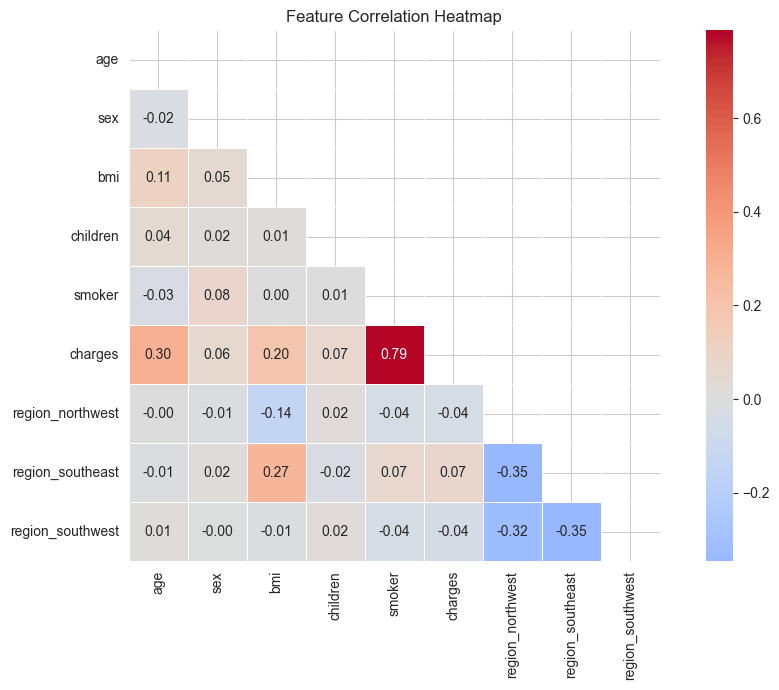

In [19]:
# Create correlation matrix using only numeric columns

numeric_df_corr = df_corr.select_dtypes(include=["int64", "float64", "int32", "float32", "bool"])

# Convert boolean columns to integers
bool_cols = numeric_df_corr.select_dtypes(include="bool").columns
numeric_df_corr[bool_cols] = numeric_df_corr[bool_cols].astype(int)

corr_matrix = numeric_df_corr.corr()

plt.figure(figsize=(10, 7))

# Show only lower triangle of correlation matrix
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

In [20]:
# Calculate correlation of each numeric feature with the target variable

target_corr = (
    numeric_df_corr.corr()["charges"]
    .drop("charges")
    .sort_values(ascending=False)
)

target_corr.round(3)

smoker              0.787
age                 0.299
bmi                 0.198
region_southeast    0.074
children            0.068
sex                 0.057
region_northwest   -0.040
region_southwest   -0.043
Name: charges, dtype: float64

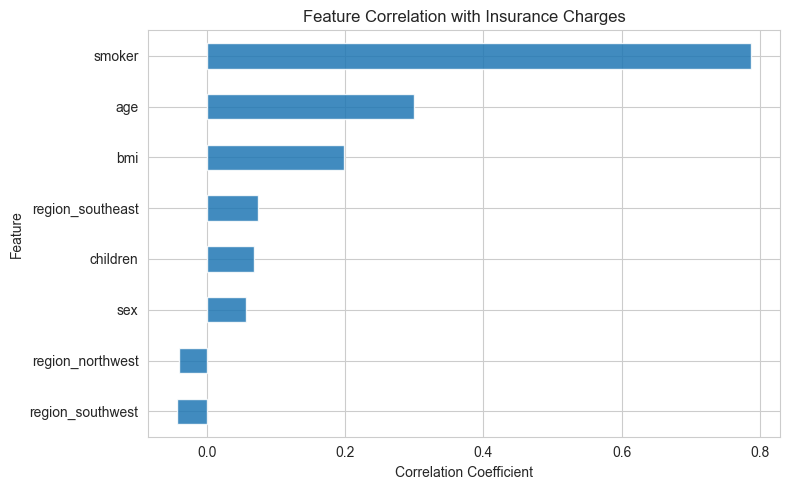

In [21]:
# Visualize correlation with insurance charges

plt.figure(figsize=(8, 5))

target_corr.sort_values().plot(kind="barh", edgecolor="white", alpha=0.85)

plt.title("Feature Correlation with Insurance Charges")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### Observation

The correlation analysis shows that `smoker` has the strongest positive correlation with insurance charges.

Important findings:

- `smoker` has a very strong positive correlation with `charges`.
- `age` has a moderate positive correlation with `charges`.
- `bmi` has a weak positive correlation with `charges`.
- `children`, `sex`, and `region` have weaker relationships with `charges`.

This confirms the earlier visual analysis where smokers had significantly higher insurance charges than non-smokers.

Therefore, smoking status is expected to be one of the most important features during model building.

## 11. Pair Plot - Top Predictors

A pair plot shows relationships between multiple features at once.

In this section, we visualize the relationship between the most important predictors and the target variable `charges`.

The selected features are:

- `age`
- `bmi`
- `children`
- `smoker`
- `charges`

The plot is separated by smoking status to understand how smokers and non-smokers differ across the main variables.

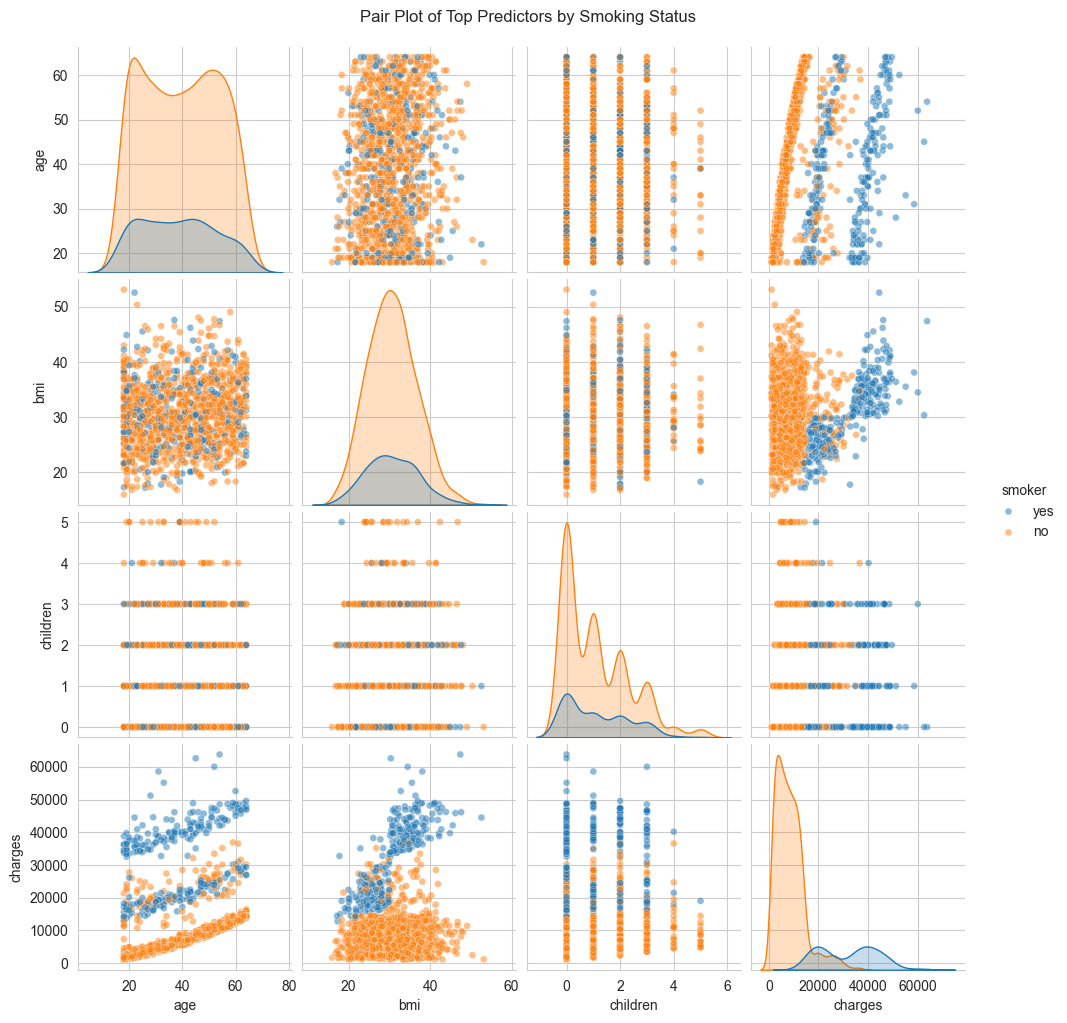

In [22]:
# Create a pair plot for selected important features

pair_plot_df = df[["age", "bmi", "children", "smoker", "charges"]].copy()

sns.pairplot(
    pair_plot_df,
    hue="smoker",
    diag_kind="kde",
    plot_kws={"alpha": 0.5, "s": 25}
)

plt.suptitle("Pair Plot of Top Predictors by Smoking Status", y=1.02)
plt.show()

### Observation

The pair plot confirms several important patterns:

- Smokers generally have much higher insurance charges than non-smokers.
- Insurance charges tend to increase with age.
- BMI shows a stronger effect when combined with smoking status.
- The number of children does not show a strong relationship with insurance charges.

This supports the previous correlation and bivariate analysis results. The most important predictors appear to be `smoker`, `age`, and `bmi`.

## 12. Key EDA Findings

The exploratory data analysis provided several important insights about the insurance cost dataset.

| # | Key Finding | Explanation |
|---|---|---|
| 1 | **Smoking status is the strongest predictor** | Smokers have much higher insurance charges compared to non-smokers. The correlation between `smoker` and `charges` is the strongest among all features. |
| 2 | **BMI increases risk when combined with smoking** | Customers who are both smokers and obese tend to have the highest average insurance charges. This suggests that a feature such as `smoker_obese` may be useful during feature engineering. |
| 3 | **Age has a positive relationship with charges** | Insurance charges generally increase as age increases. Age is one of the strongest numerical predictors in the dataset. |
| 4 | **Charges are right-skewed** | Most customers have relatively low insurance charges, while a smaller group has very high charges. A log transformation can make the target distribution more balanced. |
| 5 | **BMI has a weak positive relationship with charges** | BMI alone has some relationship with charges, but its effect becomes much clearer when combined with smoking status. |
| 6 | **Children has a weak relationship with charges** | The number of children does not show a strong direct relationship with insurance charges. |
| 7 | **Region and sex have weaker effects** | Region and sex show only small differences in insurance charges compared with smoking status, age, and BMI. |
| 8 | **Data quality is mostly good** | The dataset has no missing values, but it contains 1 duplicate row. This duplicate row should be removed in the data cleaning stage. |

## 13. EDA Conclusion

The EDA shows that medical insurance charges are mainly influenced by lifestyle and demographic factors.

The most important findings are:

- `smoker` is the most influential feature.
- `age` has a clear positive relationship with insurance charges.
- `bmi` becomes more important when combined with smoking status.
- `charges` is right-skewed, so transformation may be useful for some models.
- The dataset does not contain missing values, but it has 1 duplicate row that should be handled during data cleaning.

These insights will guide the next stage of the project, where the dataset will be cleaned, encoded, and prepared for machine learning model building.